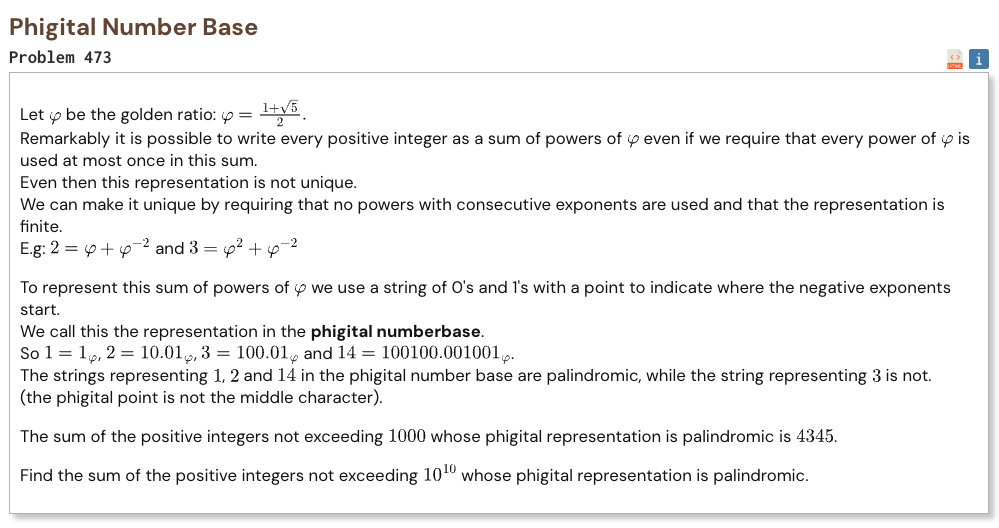

## Initial approach

- palindromic phigital integers can be built from a small sequence of integer blocks
- the block values start with 14 and 36 and every next block comes from the previous two
- choosing one block means the next two blocks cannot be chosen because consecutive exponents are forbidden
- recursively generate every valid combination whose value does not exceed the limit
- the value 2 can also appear separately but it conflicts with the first block
- include 1 as the special one digit palindrome
- add every valid value not exceeding ten billion
- no external library is needed

In [1]:
%%time

limit = 10**10

blocks = [14, 36]

while True:
    nxt = 3 * blocks[-1] - blocks[-2]

    if nxt > limit:
        break

    blocks.append(nxt)

values = set()

def generate(start, total):
    if total > limit:
        return

    values.add(total)

    for i in range(start, len(blocks)):
        new_total = total + blocks[i]

        if new_total <= limit:
            generate(i + 3, new_total)

generate(0, 0)

def generate_with_two(start, total):
    if total > limit:
        return

    values.add(total)

    for i in range(start, len(blocks)):
        new_total = total + blocks[i]

        if new_total <= limit:
            generate_with_two(i + 3, new_total)

generate_with_two(1, 2)

values.add(1)
values.discard(0)

result = sum(values)

print("Result:", result)

Result: 35856681704365
CPU times: user 3.2 ms, sys: 281 μs, total: 3.48 ms
Wall time: 3.6 ms
